# Spotify playlist completion: Assignment 2, parts 2-4

**Exploratory analysis · Modeling · Evaluation**

This notebook completes parts **2, 3, and 4 of the attached assignment PDF**.
The lecture overview numbers the topics differently; the PDF's numbering is used here.
The task is to recover withheld tracks from an existing playlist. The inputs are its
observed tracks, the fitting playlists' interactions, and optional static audio metadata;
the output is a ranked list of tracks absent from the seed playlist.

**Comparison:** a training-popularity baseline plus three distinct models:
playlist-neighborhood collaborative filtering, PureSVD latent factors, and an audio-centroid
content model. Model and feature selection use validation NDCG@20. The test set is used
only after selection. All outputs below are executed results, not illustrative numbers.

**Reading guide:** Part 2 explains the data and preprocessing; Part 3 describes the
models and implementation; Part 4 gives the evaluation protocol, comparisons, uncertainty,
and limitations. Code is included so the HTML can be reviewed without executing it.

**Scope:** this is a partial assignment deliverable covering the requested sections.
It does not include a recorded presentation or a peer-grading submission.

## 2. Exploratory analysis, data collection, and preprocessing

### 2.1 Data context and provenance

The supplied file, `data/songs620.csv`, is the dataset used throughout. Each row associates
a Spotify track with a playlist ID (`pid`) and a playlist position (`pos`). It also includes
artist/album identifiers, names, duration, and Spotify-style audio descriptors.
The filename does **not** imply that the file contains only 620 songs.

Its playlist schema and IDs 0-999 are consistent with an enriched subset of Spotify's
Million Playlist Dataset (MPD). **That origin is an inference:** the repository has no
collection script, source URL, license record, sampling description, or enrichment date,
so this notebook cannot authenticate the exact source or how the audio features were fetched.
The observed data are therefore described as the **supplied Spotify playlist CSV**.
No new Spotify API collection is performed, and URL columns are never fetched.

For context, Spotify describes the original MPD as a resource for automatic playlist
continuation, containing one million playlists and over two million tracks [R1]. That
description concerns the original dataset; this CSV is much smaller. The data contain
no listener IDs, ratings, skip logs, playlist titles, or observation timestamps. A playlist
is the recommendation context, **not a verified individual listener**. `pos` is an ordering
field rather than a timestamp, so this study makes no temporal forecasting claim.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import platform
from pathlib import Path
from time import perf_counter

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / "tmp" / "matplotlib"))
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.sparse import csr_matrix
import sklearn
from sklearn.decomposition import TruncatedSVD
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, normalize
from threadpoolctl import threadpool_limits

ROOT = Path.cwd()
OUT = ROOT / "output"
SEED = 42
K = 20
NUMERIC = ["danceability", "energy", "loudness", "speechiness", "acousticness",
           "instrumentalness", "liveness", "valence", "tempo", "duration_ms"]
CORE = ["danceability", "energy", "loudness", "valence", "tempo"]



from IPython.display import display, Image, Markdown
_thread_limit = threadpool_limits(limits=4)
assert (ROOT / 'data/songs620.csv').exists(), 'Run from the repository root.'

### 2.2 Clean interactions before splitting

An interaction is binary playlist membership: a track is either present or absent.
Repeated occurrences of a track in one playlist are collapsed **before** splitting, so
the same membership cannot appear in both a seed and its held-out targets. Distinct
playlists sharing a track are retained: that overlap is the collaborative signal.

Track metadata are checked for inconsistencies across repeated occurrences, then one
consistent record per track is used. The index column `Unnamed: 0`, redundant track IDs,
URLs, names, album fields, and `pos` do not enter the predictive models. Names are used
only for readable examples; artist IDs are used for the diversity diagnostic.

In [2]:
def load_data():
    raw = pd.read_csv(ROOT / "data/songs620.csv")
    assert raw[["pid", "track_uri"]].notna().all().all()
    edges = raw.drop_duplicates(["pid", "track_uri"]).copy()
    # Stable vocabulary from static catalogue metadata, without interaction counts.
    tracks = raw.drop_duplicates("track_uri").sort_values("track_uri").reset_index(drop=True)
    pids = np.sort(edges.pid.unique())
    track_index = {s: i for i, s in enumerate(tracks.track_uri)}
    pid_index = {p: i for i, p in enumerate(pids)}
    edges["u"] = edges.pid.map(pid_index)
    edges["i"] = edges.track_uri.map(track_index)
    return raw, edges, tracks, pids


def split_edges(edges, shape):
    rng = np.random.default_rng(SEED)
    rows = {s: [] for s in ["train", "validation", "test"]}
    for u, group in edges.groupby("u", sort=True):
        items = rng.permutation(np.sort(group.i.to_numpy()))
        assert len(items) >= 5
        # Floor each holdout at 20%; remainder belongs to train.
        h = max(1, int(len(items) * .2))
        for name, values in zip(rows, [items[2*h:], items[:h], items[h:2*h]]):
            rows[name].extend((u, int(i)) for i in values)
    matrices = {}
    for name, pairs in rows.items():
        u, i = np.array(pairs).T
        matrices[name] = csr_matrix((np.ones(len(u), dtype=np.float32), (u, i)), shape=shape)
    a, b, c = matrices.values()
    assert a.multiply(b).nnz == a.multiply(c).nnz == b.multiply(c).nnz == 0
    assert a.nnz + b.nnz + c.nnz == len(edges)
    assert all(np.all(x.getnnz(axis=1) > 0) for x in matrices.values())
    manifest = pd.concat([pd.DataFrame(pairs, columns=["u", "i"]).assign(split=name)
                          for name, pairs in rows.items()], ignore_index=True)
    manifest.to_csv(OUT / "split_manifest.csv", index=False)
    return matrices


def audio_features(tracks, observed, representation):
    cols = CORE if representation == "core" else NUMERIC
    x = tracks[cols].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    # Avoid letting an extreme duration dominate the geometry.
    if "duration_ms" in cols:
        x["duration_ms"] = np.log1p(x["duration_ms"].clip(lower=0))
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    x_fit = imputer.fit_transform(x.loc[observed])
    scaler = StandardScaler().fit(x_fit)
    z = scaler.transform(imputer.transform(x)).astype(np.float32)
    if representation == "full":
        # Fixed semantic categories: no category order is assumed.
        cats = []
        for col, values in [("key", range(-1, 12)), ("mode", [-1, 0, 1]),
                            ("time_signature", range(-1, 8))]:
            v = pd.to_numeric(tracks[col], errors="coerce").fillna(-1).to_numpy()
            cats.extend((v == value).astype(np.float32)[:, None] for value in values)
        z = np.hstack([z] + cats)
    return normalize(z).astype(np.float32)


def run_eda(raw, edges, tracks, train):
    sizes = edges.groupby("pid").size()
    freq = edges.groupby("track_uri").size().sort_values(ascending=False)
    summary = {
        "raw_rows": len(raw), "unique_interactions": len(edges),
        "duplicate_playlist_track_rows": len(raw)-len(edges),
        "playlists": edges.pid.nunique(), "tracks": len(tracks),
        "artists": tracks.artist_uri.nunique(),
        "density": len(edges)/(edges.pid.nunique()*len(tracks)),
        "singleton_tracks": int((freq == 1).sum()),
        "singleton_track_fraction": float((freq == 1).mean()),
        "top_1pct_interaction_share": float(freq.iloc[:int(np.ceil(.01*len(freq)))].sum()/len(edges)),
        "playlist_size": {k: float(v) for k,v in sizes.describe().items()},
        "missing_by_column": {k:int(v) for k,v in raw.isna().sum().items()},
        "pid_min": int(edges.pid.min()), "pid_max": int(edges.pid.max()),
        "metadata_conflicting_tracks": int((raw.groupby("track_uri")[NUMERIC + ["key", "mode", "time_signature", "artist_uri"]].nunique(dropna=False).max(axis=1)>1).sum()),
    }
    summary["invalid_numeric_values"] = {}
    for col in NUMERIC:
        v = pd.to_numeric(tracks[col], errors="coerce")
        summary["invalid_numeric_values"][col] = int((~np.isfinite(v)).sum())
    tracks[NUMERIC].describe().T.to_csv(OUT / "audio_summary.csv")
    pd.DataFrame({"column": raw.columns, "missing": raw.isna().sum().to_numpy()}).to_csv(OUT / "missingness.csv", index=False)
    raw.groupby("track_uri").size().rename("row_count").to_csv(OUT / "track_frequencies.csv")
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
    fig, ax = plt.subplots(1,3,figsize=(14,3.7), layout="constrained")
    ax[0].hist(sizes, bins=25, color="#237a69")
    ax[0].set(xlabel="Unique tracks per playlist", ylabel="Playlists", title="Playlist length")
    ax[1].loglog(np.arange(1,len(freq)+1), freq.values, color="#386ba8")
    ax[1].set(xlabel="Track popularity rank (log)", ylabel="Playlist count (log)", title="Long-tail interactions")
    corr = tracks[["danceability","energy","loudness","acousticness","valence","tempo"]].corr()
    im = ax[2].imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax[2].set(xticks=range(6), yticks=range(6), yticklabels=corr.columns, title="Track-level correlations")
    ax[2].set_xticklabels(corr.columns, rotation=65, ha="right")
    fig.colorbar(im, ax=ax[2], shrink=.8)
    fig.savefig(OUT / "eda.png", dpi=160)
    plt.close(fig)
    # Training-only evidence for feature relevance; one centroid does not presume
    # that every playlist is acoustically homogeneous.
    z = audio_features(tracks, np.asarray(train.sum(axis=0)).ravel()>0, "core")
    rng = np.random.default_rng(SEED)
    within, random = [], []
    for u in range(train.shape[0]):
        ids = train[u].indices
        n = min(20, len(ids))
        for _ in range(n):
            a,b = rng.choice(ids, 2, replace=False)
            within.append(float(z[a] @ z[b]))
            a,b = rng.choice(len(tracks),2,replace=False)
            random.append(float(z[a] @ z[b]))
    summary["training_audio_cosine_within_mean"] = float(np.mean(within))
    summary["catalogue_audio_cosine_random_mean"] = float(np.mean(random))
    summary["audio_energy_loudness_correlation"] = float(tracks.energy.corr(tracks.loudness))
    fig,ax = plt.subplots(figsize=(7,3.2), layout="constrained")
    ax.hist(within,bins=40,density=True,alpha=.6,label="Within training playlist")
    ax.hist(random,bins=40,density=True,alpha=.5,label="Random catalogue pair")
    ax.set(xlabel="Cosine similarity of standardized core audio features", ylabel="Density", title="Do audio features reflect playlist coherence?")
    ax.legend()
    fig.savefig(OUT / "audio_coherence.png",dpi=160)
    plt.close(fig)
    (OUT / "eda_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    return summary

In [3]:
OUT.mkdir(exist_ok=True)
raw, edges, tracks, pids = load_data()
shape = (len(pids),len(tracks))
matrices = split_edges(edges, shape)
train, validation, test = matrices.values()
tracks[["track_uri","artist_uri","track_name","artist_name"]].to_csv(OUT / "item_vocabulary.csv",index=False)
pd.DataFrame({"u": np.arange(len(pids)), "pid":pids}).to_csv(OUT / "playlist_vocabulary.csv",index=False)
summary = run_eda(raw, edges, tracks, train)
print("EDA:", json.dumps({k:summary[k] for k in ["raw_rows","unique_interactions","tracks","singleton_track_fraction"]}),flush=True)

EDA: {"raw_rows": 66263, "unique_interactions": 65409, "tracks": 36203, "singleton_track_fraction": 0.7430599674060161}


,Quantity,Value
0,Raw rows,66263
1,Repeated playlist-track rows removed,854
2,Unique memberships,65409
3,Playlists,1000
4,Tracks,36203
5,Artists,9963
6,Singleton tracks,26901
7,Interaction density,0.1807%


,Unique playlist size
count,1000.00
mean,65.41
std,53.39
min,5.00
25%,24.00
50%,49.00
75%,90.00
max,246.00


,count,mean,std,min,25%,50%,75%,max
danceability,36203.0,0.576,0.171,0.0,0.467,0.588,0.700,0.988
energy,36203.0,0.628,0.234,0.0,0.475,0.665,0.817,0.999
loudness,36203.0,-7.945,4.507,-60.0,-9.497,-6.810,-5.027,1.589
speechiness,36203.0,0.086,0.092,0.0,0.035,0.047,0.089,0.949
acousticness,36203.0,0.271,0.306,0.0,0.020,0.131,0.465,0.996
instrumentalness,36203.0,0.097,0.248,0.0,0.000,0.000,0.006,0.997
liveness,36203.0,0.195,0.167,0.0,0.096,0.126,0.248,0.997
valence,36203.0,0.479,0.251,0.0,0.276,0.470,0.677,1.000
tempo,36203.0,121.208,29.398,0.0,97.968,120.462,139.993,248.060
duration_ms,36203.0,235145.987,77339.804,4120.0,194905.500,224720.000,262083.000,1943459.000


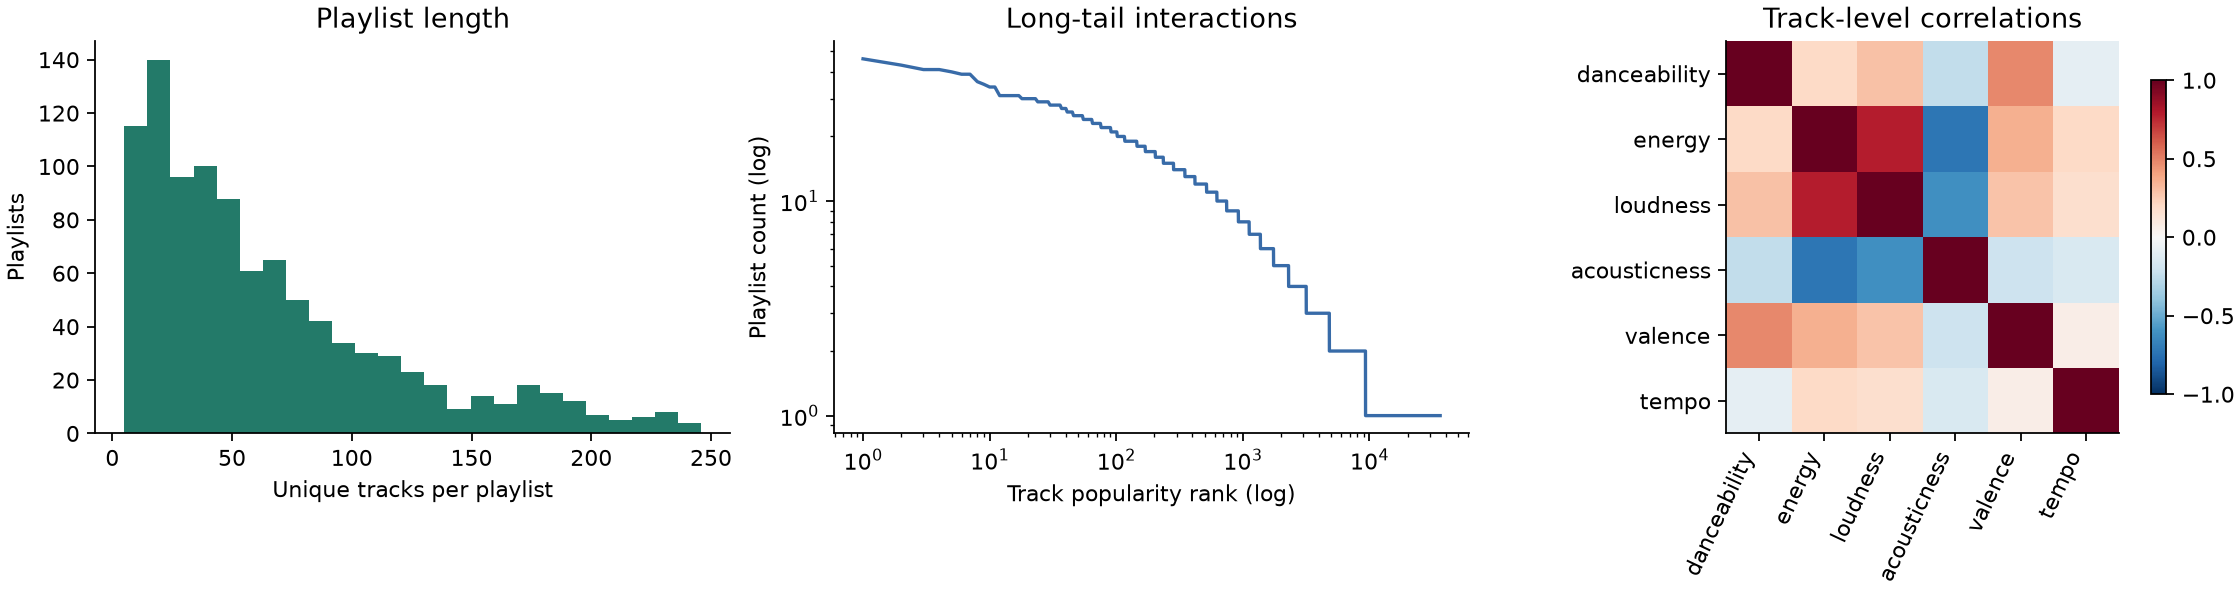

In [4]:
overview = pd.DataFrame({
    'Quantity': ['Raw rows', 'Repeated playlist-track rows removed', 'Unique memberships',
                 'Playlists', 'Tracks', 'Artists', 'Singleton tracks', 'Interaction density'],
    'Value': [summary['raw_rows'], summary['duplicate_playlist_track_rows'],
              summary['unique_interactions'], summary['playlists'], summary['tracks'],
              summary['artists'], summary['singleton_tracks'], f"{summary['density']:.4%}"]})
display(overview)
display(pd.DataFrame(summary['playlist_size'], index=['Unique playlist size']).T.round(2))
display(pd.read_csv(OUT / 'audio_summary.csv', index_col=0).round(3))
display(Image(filename=str(OUT / 'eda.png')))

### 2.3 What the data show, and why it matters

There are **66,263 raw rows**, reduced to **65,409 unique playlist-track memberships**
after removing **854 repeated memberships**. The file contains **1,000 playlists**,
**36,203 tracks**, and **9,963 artists**. Only **0.181%** of the playlist-track matrix
is observed. Playlist lengths range from 5 to 246 unique tracks, with a median of 49.

The track distribution has a substantial long tail: **26,901 tracks (74.3%) appear in
only one playlist**, while the most frequent 1% of tracks account for 10.5% of unique
memberships. Popularity is therefore a relevant baseline, but many test targets will
lack collaborative evidence. This motivates comparing a content model with two
collaborative models, and reporting warm-track and cold-track performance separately.

No supplied column has missing values, and the numerical model inputs are finite.
Repeated metadata records agree for all modeled features and artist IDs. A defensive
median imputer remains in the content pipeline; it is fitted only on tracks observed
in fitting interactions. Duration is log-transformed and continuous features are
standardized on those same fitting tracks. Held-out track metadata can be transformed
because the catalogue is assumed known; their interaction labels are never used to fit
preprocessing. Zero tempo or energy values are retained as supplied rather than silently
interpreted as missing. Their upstream meaning cannot be checked from this CSV.

Energy and loudness correlate strongly at the unique-track level (Pearson r = 0.788).
This suggests redundant descriptors and motivates testing a compact feature set against
a fuller one. Correlation alone does not establish predictive usefulness.

,column,missing
0,Unnamed: 0,0
1,pid,0
2,pos,0
3,artist_name,0
4,track_uri,0
5,artist_uri,0
6,track_name,0
7,album_uri,0
8,duration_ms,0
9,album_name,0


Tracks with conflicting modeled metadata: 0
Non-finite numerical values: 0
Training within-playlist mean core-audio cosine: 0.236
Random catalogue-pair mean core-audio cosine: 0.0135


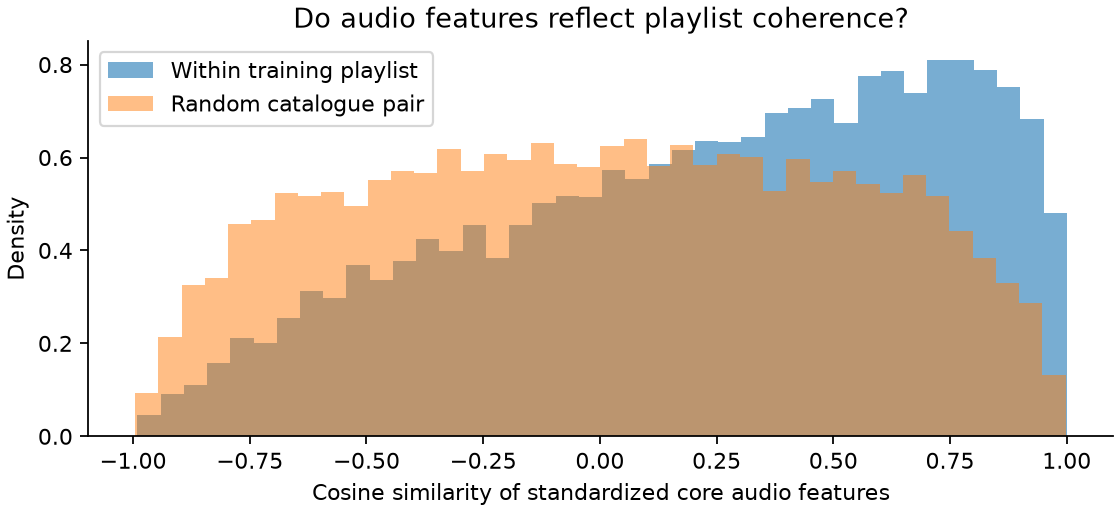

In [5]:
display(pd.read_csv(OUT / 'missingness.csv'))
print('Tracks with conflicting modeled metadata:', summary['metadata_conflicting_tracks'])
print('Non-finite numerical values:', sum(summary['invalid_numeric_values'].values()))
print('Training within-playlist mean core-audio cosine:',
      round(summary['training_audio_cosine_within_mean'], 4))
print('Random catalogue-pair mean core-audio cosine:',
      round(summary['catalogue_audio_cosine_random_mean'], 4))
display(Image(filename=str(OUT / 'audio_coherence.png')))

The training-only within-playlist pair sample has mean audio cosine similarity **0.2360**,
versus **0.0135** for random catalogue pairs. This is descriptive evidence that audio
features capture some playlist coherence. Pairs share playlists and tracks, so they are
not treated as independent observations for a significance test. Similar audio also
does not guarantee recovery of an exact withheld track from 36,203 candidates.

### 2.4 Split and information boundary

Within each playlist, unique tracks are shuffled using seed 42. Two disjoint sets of
`floor(0.2 * playlist_length)` tracks are assigned to validation and test; the remainder
forms training. All playlists have at least five tracks, so every partition has at
least one interaction per playlist. The resulting split has **40,013 training**,
**12,698 validation**, and **12,698 test** memberships.

During selection, models fit only the training matrix and recommend against validation
targets. After all configurations are frozen, each model is refitted on training plus
validation (**52,711 memberships**) and recommends against the untouched test targets.
This uses the validation tracks as additional seeds at final evaluation, for every model.
Validation and test scores consequently have different seed lengths and are not a
train-test generalization-gap estimate.

This is a **random missing-track completion** experiment on known playlists and a known
static catalogue. It does not measure new-playlist performance, future listening,
track ordering, or chronological next-song prediction. Tracks may occur in several
playlists; each individual membership is assigned exactly once. The complete mapping
is saved in `output/split_manifest.csv` with separate item and playlist vocabularies.

In [6]:
display(pd.DataFrame({'split': list(matrices),
                      'memberships': [m.nnz for m in matrices.values()]}))
assert train.multiply(validation).nnz == 0
assert train.multiply(test).nnz == 0
assert validation.multiply(test).nnz == 0
assert (train + validation + test).nnz == len(edges)
print('Verified: disjoint memberships, complete accounting, and nonempty playlist partitions.')

,split,memberships
0,train,40013
1,validation,12698
2,test,12698


Verified: disjoint memberships, complete accounting, and nonempty playlist partitions.


## 3. Modeling

### 3.1 Inputs, outputs, and course connections

Let $B_{pi}=1$ when fitting playlist $p$ contains track $i$, and zero otherwise.
For each playlist the model outputs a score $s(p,i)$ for every track in the catalogue.
Observed seed tracks are removed before taking the highest scores. Unobserved
memberships are **unknown**, rather than explicit dislikes.

The lecture `recommendation.pdf` [L1] introduces cosine similarity, neighborhood
collaborative filtering, low-dimensional latent factors, implicit feedback, and ranking
metrics. Those ideas motivate the first two learned approaches and the evaluation.
`regression.pdf` [L2] motivates categorical encodings, feature transforms, control of
model complexity, and a distinct validation set. The implementation uses those ideas
for audio features and model selection. The latent-factor model below is a truncated
SVD adaptation, not a claim to reproduce the lecture's rating-loss optimizer exactly.

### 3.2 Baseline and three models

| Method | Score or objective | Role and tradeoff |
|---|---|---|
| Popularity baseline | $s(p,i)=\sum_q B_{qi}$ | Ranks tracks by fitting playlist count. Cheap and robust, but has no playlist-specific preferences and favors popular tracks. |
| Playlist-kNN collaborative filtering | $c(p,q)=B_pB_q^T/(\|B_p\|\|B_q\|)$; $s(p,i)=\sum_{q\in N_k(p),q\ne p}c(p,q)^a B_{qi}$ | Uses shared tracks to find related playlists. Interpretable, but sparse overlap and cold items are difficult. The diagonal similarity is set to zero. |
| PureSVD latent factors | Approximate $\min_{\mathrm{rank}(\hat B)\le d}\|B-\hat B\|_F^2$ using randomized truncated SVD; $\hat B=(BV_d)V_d^T$ | Low-rank representations share information across playlists. Rank limits complexity. The zero-filled reconstruction objective is only a surrogate for ranking and gives unknown entries a zero target. |
| Audio centroid content model | Normalize item feature vectors $z_i$; $h_p=\mathrm{normalize}(\sum_{i:B_{pi}=1}z_i)$; $s(p,i)=h_p^Tz_i$ | Fits scaling from known tracks and builds a playlist profile. It can score catalogue tracks without fitting interactions. A single centroid may blur mixed-genre playlists and cannot capture all cultural or semantic preferences. |

PureSVD uses `TruncatedSVD` with seven power iterations and fixed randomness. The
returned transformed matrix is $BV_d$, so multiplying by `components_` produces the
rank-$d$ reconstruction. There is no stochastic-gradient learning rate or early
stopping to tune. Its chosen rank is selected only with validation NDCG@20.

The centroid is a content model fitted through preprocessing and profile construction;
it does not learn a supervised neural network. The three models represent neighborhood,
latent-factor, and content-based approaches, in addition to the baseline.

### 3.3 Feature representations and hyperparameter search

**Collaborative features:** a sparse binary playlist-track matrix. Frequencies are
computed after deduplication, not from repeated positions. Neither collaborative model
uses audio, names, artist IDs, or test interactions.

**Core audio representation:** danceability, energy, loudness, valence, and tempo.
**Full representation:** those five plus speechiness, acousticness, instrumentalness,
liveness, and log-duration, followed by fixed one-hot encodings of key, mode, and time
signature. The encodings avoid imposing a numerical ordering on categories; they do
not model harmonic distance. Reserved categories make the full vector 35-dimensional.
Continuous columns are standardized; category indicator columns remain 0/1. Each
resulting item vector is L2-normalized. These choices impose equal coordinate weights
rather than learning the ideal importance of each descriptor.

The predefined grid contains **12 configurations**: popularity (1), kNN with
neighbors in {20, 50, 100} and similarity power in {1, 2} (6), SVD with rank in
{16, 32, 64} (3), and core/full audio (2). Each model family selects its highest
validation NDCG@20 configuration. A stable first-configuration rule breaks any exact
ties. No grid is expanded after inspecting test scores.

In [7]:
class Ranker:
    """Small score interface; no test labels are accepted by this class."""
    def __init__(self, name, parameters=None):
        self.name, self.parameters = name, parameters or {}

    def fit(self, interactions, tracks):
        start = perf_counter()
        self.b = interactions.tocsr().astype(np.float32)
        self.pop = np.asarray(self.b.sum(axis=0)).ravel()
        self.n_items = self.b.shape[1]
        if self.name == "Playlist-kNN":
            b_norm = normalize(self.b)
            similarity = (b_norm @ b_norm.T).toarray()
            np.fill_diagonal(similarity, 0)  # Never use a playlist as its own neighbor.
            k = self.parameters["neighbors"]
            neighbors = np.argsort(-similarity, axis=1, kind="stable")[:, :k]
            u = np.repeat(np.arange(self.b.shape[0]), k)
            v = neighbors.ravel()
            weights = similarity[u, v] ** self.parameters["power"]
            self.w = csr_matrix((weights, (u, v)), shape=similarity.shape)
        elif self.name == "PureSVD":
            self.svd = TruncatedSVD(n_components=self.parameters["rank"], n_iter=7,
                                    random_state=SEED)
            self.embedding = self.svd.fit_transform(self.b)
        elif self.name == "Audio centroid":
            self.features = audio_features(tracks, self.pop > 0, self.parameters["features"])
            self.profiles = normalize(np.asarray(self.b @ self.features))
        elif self.name != "Popularity":
            raise ValueError(self.name)
        self.fit_seconds = perf_counter() - start
        return self

    def scores(self, first, last):
        if self.name == "Popularity":
            return np.broadcast_to(self.pop, (last-first, self.n_items)).copy()
        if self.name == "Playlist-kNN":
            return (self.w[first:last] @ self.b).toarray()
        if self.name == "PureSVD":
            return self.embedding[first:last] @ self.svd.components_
        return self.profiles[first:last] @ self.features.T


def top_items(scores, seen, popularity, k=50):
    """Exact top-k, with deterministic popularity then item-ID tie breaks."""
    scores = np.asarray(scores).copy()
    scores[seen] = -np.inf
    assert np.isfinite(scores[~seen]).all()
    cutoff = np.partition(scores, len(scores)-k)[len(scores)-k]
    above = np.flatnonzero(scores > cutoff)
    tied = np.flatnonzero(scores == cutoff)
    tied = tied[np.lexsort((tied, -popularity[tied]))][:k-len(above)]
    selected = np.r_[above, tied]
    return selected[np.lexsort((selected, -popularity[selected], -scores[selected]))]


def recommend(model, max_k=50):
    start = perf_counter()
    ranked = []
    for first in range(0, model.b.shape[0], 32):
        last = min(first+32, model.b.shape[0])
        scores = model.scores(first, last)
        for offset, u in enumerate(range(first, last)):
            seen = np.zeros(model.n_items, dtype=bool)
            seen[model.b[u].indices] = True
            top = top_items(scores[offset], seen, model.pop, max_k)
            assert len(np.unique(top)) == max_k and not seen[top].any()
            ranked.append(top)
    return np.array(ranked), perf_counter()-start

### 3.4 Architectural choices, efficiency, and overfitting

The binary matrix uses SciPy CSR storage, with one stored value per fitting
membership. The kNN implementation builds the playlist-by-playlist similarity matrix,
then retains only the selected neighbors. With 1,000 playlists this dense intermediate
is approximately 4 MB in float32. It is practical here, but its quadratic playlist
memory would be inappropriate at MPD scale; approximate neighbor retrieval or blocked
similarity search would be needed there.

SVD stores approximately $d(P+I)$ factor entries, and content scoring stores $I F$
item-feature entries. Ranking scores are generated in batches of 32 playlists, avoiding
a full playlist-by-catalogue score matrix. A batch of 32 by 36,203 float32 scores is
about 4.6 MB. CSR interactions and batched multiplication keep this dataset small
enough for CPU execution. Reported times cover fitting and top-50 scoring/ranking,
not CSV parsing, EDA, metric calculation, or bootstrap uncertainty.

Top-k selection uses partitioning, with explicit tie handling: descending model score,
then descending fitting popularity, then stable track ID. Thus every model uses the
same deterministic fallback for tied or unsupported predictions. Content scores can
be negative after centering; their ordering remains valid. Seed tracks are always
masked, and a playlist is never its own kNN neighbor.

The rank constraint regularizes SVD; k and the similarity power control neighborhood
locality. The audio model has no supervised coefficient fitting, but representation
selection still risks validation overfitting. A fixed grid and a held-out test set
limit that risk. Training reconstruction is not reported as recommendation quality,
since rewarding recovery of already-seen tracks would be misleading.

Rating regression is not directly supported because no ratings exist. Ordinary
accuracy on all playlist-track pairs would be dominated by missing entries. A
sequence transformer would require a different ordered-task design and substantially
more training context. These models could be studied later, but are not necessary
to compare the course's similarity and latent-factor approaches here.

## 4. Evaluation

### 4.1 Metrics and candidate set

Every model ranks the **entire 36,203-track catalogue**, removing only tracks in that
playlist's fitting seed. No sampled negative set or minimum-popularity filter is used.
Validation targets are not removed during validation; test targets are not removed
during test evaluation. Catalogue metadata are assumed available even for tracks with
zero fitting interactions.

The primary metric is **macro NDCG@20**, which rewards retrieving relevant tracks near
the top of a short recommendation list. For held-out set $T_p$, and relevance
$r_{pj}=1$ if the track at rank $j$ is in $T_p$:

$$\mathrm{DCG@K}(p)=\sum_{j=1}^{K}\frac{r_{pj}}{\log_2(j+1)},\qquad
\mathrm{NDCG@K}(p)=\frac{\mathrm{DCG@K}(p)}
{\sum_{j=1}^{\min(K,|T_p|)}1/\log_2(j+1)}.$$

**Recall@K** is the number of retrieved targets divided by $|T_p|$;
**Precision@K** divides by K; **HitRate@K** is one if at least one target is retrieved.
Each metric is averaged equally over playlists, so long playlists do not dominate.
We report K = 10, 20, and 50, with K = 20 fixed before selection.

**Coverage@20** is the number of distinct tracks recommended across all playlists
divided by the catalogue size. **Artist diversity@20** is the mean number of distinct
artists per list divided by 20. **Novelty@20** is the mean
$\log_2((P+1)/(n_i+1))$ of recommended tracks, using fitting playlist count $n_i$.
Higher novelty therefore means lower fitting popularity; it is not evidence that a
listener enjoys the recommendations.

NDCG and recall match the recovery task more directly than MSE, which would compare
scores without calibrated rating labels, or classification accuracy, which treats
nearly all unknown pairs as negatives. Ranking relevance is still incomplete:
unobserved tracks could be enjoyable, so this is exact-membership recovery rather
than a direct measure of satisfaction. The metrics are not numerically comparable
to the official MPD challenge's differently configured evaluation [R2].

In [8]:
def evaluate(ranked, target, fit_matrix, tracks):
    rows = []
    pop = np.asarray(fit_matrix.sum(axis=0)).ravel()
    artists = tracks.artist_uri.fillna("unknown").to_numpy()
    discounts = 1 / np.log2(np.arange(2, 52))
    for u, recs in enumerate(ranked):
        truth = target[u].indices
        hits = np.isin(recs, truth)
        row = {"u": u, "target_count": len(truth), "seed_count": fit_matrix[u].nnz}
        for k in [10, 20, 50]:
            h = hits[:k].sum()
            row.update({f"Recall@{k}": h/len(truth), f"Precision@{k}": h/k,
                        f"NDCG@{k}": float(hits[:k] @ discounts[:k]) / discounts[:min(k,len(truth))].sum(),
                        f"HitRate@{k}": float(h > 0)})
        warm, cold = truth[pop[truth] > 0], truth[pop[truth] == 0]
        row["WarmRecall@20"] = np.isin(recs[:20], warm).sum()/len(warm) if len(warm) else np.nan
        row["ColdRecall@20"] = np.isin(recs[:20], cold).sum()/len(cold) if len(cold) else np.nan
        row["cold_targets"] = len(cold)
        row["Novelty@20"] = float(np.mean(np.log2((fit_matrix.shape[0]+1)/(pop[recs[:20]]+1))))
        row["ArtistDiversity@20"] = len(np.unique(artists[recs[:20]]))/20
        rows.append(row)
    return pd.DataFrame(rows)


def paired_uncertainty(a, b):
    """Percentile paired bootstrap + two-sided paired sign-flip test."""
    rng = np.random.default_rng(2026)
    d = np.asarray(a) - np.asarray(b)
    boot = d[rng.integers(0, len(d), size=(2000, len(d)))].mean(axis=1)
    extreme = 0
    for _ in range(20):
        perm = (rng.choice([-1, 1], size=(500, len(d))) * d).mean(axis=1)
        extreme += np.count_nonzero(np.abs(perm) >= abs(d.mean()) - 1e-15)
    lo, hi = np.quantile(boot, [.025, .975])
    return float(d.mean()), float(lo), float(hi), (extreme+1)/10001

### 4.2 Validation selection

The following code runs the declared grid, computes validation metrics, and freezes
one configuration per family. It chooses the overall model by validation NDCG@20,
not by the test leaderboard. The full grid is retained to show the feature ablation
and sensitivity to model complexity.

In [9]:
configs = [("Popularity", {})]
configs += [("Playlist-kNN", {"neighbors":k, "power":p}) for k in [20,50,100] for p in [1,2]]
configs += [("PureSVD", {"rank":r}) for r in [16,32,64]]
configs += [("Audio centroid", {"features":f}) for f in ["core","full"]]
validation_rows = []
for name,parameters in configs:
    model = Ranker(name,parameters).fit(train, tracks)
    ranked, seconds = recommend(model)
    metrics = evaluate(ranked,validation,train,tracks)
    row = {"model":name,"parameters":json.dumps(parameters,sort_keys=True),
           "fit_seconds":model.fit_seconds,"rank_seconds":seconds,
           **{k:float(metrics[k].mean()) for k in ["NDCG@20","Recall@20","Precision@20"]}}
    validation_rows.append(row)
    print("Validation:", json.dumps(row),flush=True)
val_table = pd.DataFrame(validation_rows)
val_table.to_csv(OUT / "validation_results.csv",index=False)
# Stable tie: earlier configuration in the declared grid wins.
selected = {name: group.loc[group["NDCG@20"].idxmax()].to_dict()
            for name,group in val_table.groupby("model",sort=False)}
winner = max(selected, key=lambda n:selected[n]["NDCG@20"])

Validation: {"model": "Popularity", "parameters": "{}", "fit_seconds": 0.0003250997979193926, "rank_seconds": 0.420873099938035, "NDCG@20": 0.008317954734712767, "Recall@20": 0.009218303746014614, "Precision@20": 0.005550000000000001}


Validation: {"model": "Playlist-kNN", "parameters": "{\"neighbors\": 20, \"power\": 1}", "fit_seconds": 0.013727599987760186, "rank_seconds": 0.6338150999508798, "NDCG@20": 0.05251270440975796, "Recall@20": 0.05441603624464344, "Precision@20": 0.03185}


Validation: {"model": "Playlist-kNN", "parameters": "{\"neighbors\": 20, \"power\": 2}", "fit_seconds": 0.014584599994122982, "rank_seconds": 0.6674458000343293, "NDCG@20": 0.04882882407382432, "Recall@20": 0.050464470208316084, "Precision@20": 0.029500000000000002}


Validation: {"model": "Playlist-kNN", "parameters": "{\"neighbors\": 50, \"power\": 1}", "fit_seconds": 0.014576800167560577, "rank_seconds": 0.6504371999762952, "NDCG@20": 0.05658350310131444, "Recall@20": 0.059179667240297607, "Precision@20": 0.03395}


Validation: {"model": "Playlist-kNN", "parameters": "{\"neighbors\": 50, \"power\": 2}", "fit_seconds": 0.013779300032183528, "rank_seconds": 0.6771770000923425, "NDCG@20": 0.052054844174244566, "Recall@20": 0.05367660117465186, "Precision@20": 0.03125}


Validation: {"model": "Playlist-kNN", "parameters": "{\"neighbors\": 100, \"power\": 1}", "fit_seconds": 0.015786899952217937, "rank_seconds": 0.7225122000090778, "NDCG@20": 0.05591930981885388, "Recall@20": 0.058737536776049384, "Precision@20": 0.03385}


... (2 outputs left out)

Validation: {"model": "PureSVD", "parameters": "{\"rank\": 32}", "fit_seconds": 0.13217359990812838, "rank_seconds": 0.3570314000826329, "NDCG@20": 0.039150330140646644, "Recall@20": 0.042604287354118434, "Precision@20": 0.0255}


Validation: {"model": "PureSVD", "parameters": "{\"rank\": 64}", "fit_seconds": 0.25956729985773563, "rank_seconds": 0.3694625999778509, "NDCG@20": 0.04202491664416945, "Recall@20": 0.04276688784376782, "Precision@20": 0.02745}


Validation: {"model": "Audio centroid", "parameters": "{\"features\": \"core\"}", "fit_seconds": 0.013206300092861056, "rank_seconds": 0.2437206998001784, "NDCG@20": 0.004419000765300464, "Recall@20": 0.00475830241977163, "Precision@20": 0.003}


Validation: {"model": "Audio centroid", "parameters": "{\"features\": \"full\"}", "fit_seconds": 0.03390670008957386, "rank_seconds": 0.25131630012765527, "NDCG@20": 0.009321851104511301, "Recall@20": 0.011304258088630992, "Precision@20": 0.00525}


In [10]:
display(val_table[['model','parameters','NDCG@20','Recall@20','Precision@20']].round(5))
print('Frozen validation-selected model:', winner)
display(pd.DataFrame(selected).T[['parameters','NDCG@20']])

,model,parameters,NDCG@20,Recall@20,Precision@20
0,Popularity,{},0.00832,0.00922,0.00555
1,Playlist-kNN,"{""neighbors"": 20, ""power"": 1}",0.05251,0.05442,0.03185
2,Playlist-kNN,"{""neighbors"": 20, ""power"": 2}",0.04883,0.05046,0.02950
3,Playlist-kNN,"{""neighbors"": 50, ""power"": 1}",0.05658,0.05918,0.03395
4,Playlist-kNN,"{""neighbors"": 50, ""power"": 2}",0.05205,0.05368,0.03125
5,Playlist-kNN,"{""neighbors"": 100, ""power"": 1}",0.05592,0.05874,0.03385
6,Playlist-kNN,"{""neighbors"": 100, ""power"": 2}",0.05226,0.05439,0.03170
7,PureSVD,"{""rank"": 16}",0.03446,0.03762,0.02185
8,PureSVD,"{""rank"": 32}",0.03915,0.04260,0.02550
9,PureSVD,"{""rank"": 64}",0.04202,0.04277,0.02745


Frozen validation-selected model: Playlist-kNN


,parameters,NDCG@20
Popularity,{},0.008318
Playlist-kNN,"{""neighbors"": 50, ""power"": 1}",0.056584
PureSVD,"{""rank"": 64}",0.042025
Audio centroid,"{""features"": ""full""}",0.009322


Validation selects **50 neighbors with power 1**, **SVD rank 64**, and the **full audio
representation**. Audio validation NDCG@20 increases from **0.00442** for the core
representation to **0.00932** for the full one. Because several descriptors and
categorical features change together, this comparison does not isolate which added
feature causes the gain. The fixed grid ends at rank 64, so this study does not claim
that rank 64 is globally optimal. Increasing k from 50 to 100 does not improve the
validation score; a broader neighborhood is not automatically better.

### 4.3 Final refit, test evaluation, and uncertainty

Each frozen configuration is refitted on train plus validation. The next code is the
first experiment stage that uses test labels. It saves per-playlist results and
top-50 recommendations so the aggregate values can be audited.

For the primary metric, **2,000 paired bootstrap samples of playlists** produce a
95% percentile interval for each model's difference from popularity. We also use a
**10,000-draw two-sided paired sign-flip test** with the +1 Monte Carlo correction.
Holm adjustment covers the three model-versus-baseline tests. Mean-score intervals
on the plot also resample playlists. These intervals are conditional on this split
and fitted models; shared tracks and overlapping playlist tastes mean playlist
independence is an approximation. They do not quantify uncertainty from recollecting
the dataset, changing the split, or refitting on bootstrap datasets.

In [11]:
fit_matrix = (train + validation).tocsr()
final_rows, all_per_playlist, ranks = [], {}, {}
for name,selection in selected.items():
    model = Ranker(name,json.loads(selection["parameters"])).fit(fit_matrix,tracks)
    ranked,seconds = recommend(model)
    metrics = evaluate(ranked,test,fit_matrix,tracks)
    ranks[name], all_per_playlist[name] = ranked, metrics
    metrics.assign(model=name).to_csv(OUT / (name.lower().replace(" ","_")+"_per_playlist.csv"),index=False)
    np.save(OUT / (name.lower().replace(" ","_")+"_top50.npy"),ranked)
    row = {"model":name, "parameters":selection["parameters"],
           **{c:float(metrics[c].mean()) for c in metrics if "@" in c},
           "Coverage@20":len(np.unique(ranked[:,:20]))/shape[1],
           "fit_seconds":model.fit_seconds,"rank_seconds":seconds}
    final_rows.append(row)
    print("Test:",json.dumps(row),flush=True)
result_table = pd.DataFrame(final_rows)
result_table.to_csv(OUT / "test_results.csv",index=False)
base = all_per_playlist["Popularity"]["NDCG@20"]
uncertainty = []
for name in selected:
    if name == "Popularity": continue
    delta,lo,hi,p = paired_uncertainty(all_per_playlist[name]["NDCG@20"],base)
    uncertainty.append({"model":name,"delta_ndcg20_vs_popularity":delta,
                        "ci_low":lo,"ci_high":hi,"p_two_sided":p})
uncertainty = pd.DataFrame(uncertainty)
order = np.argsort(uncertainty.p_two_sided.to_numpy())
adjusted = np.maximum.accumulate(np.minimum(1,uncertainty.p_two_sided.to_numpy()[order] * np.arange(len(order),0,-1)))
uncertainty.loc[order,"p_holm"] = adjusted
uncertainty.to_csv(OUT / "paired_comparisons.csv",index=False)
# Confidence interval on each model mean, resampling playlists as the unit.
rng = np.random.default_rng(2026)
indices = rng.integers(0,shape[0],size=(2000,shape[0]))
ci = {}
for name,m in all_per_playlist.items():
    ci[name] = np.quantile(m["NDCG@20"].to_numpy()[indices].mean(axis=1),[.025,.975]).tolist()
length = np.asarray(fit_matrix.sum(axis=1)).ravel()
# Fixed cutpoints give transparent groups and avoid ambiguous quantile ties.
bins = pd.cut(length, bins=[0,20,50,np.inf],labels=["1-20 seeds","21-50 seeds","51+ seeds"])
subgroup = []
for name,m in all_per_playlist.items():
    g=m.assign(length_group=bins).groupby("length_group",observed=True).agg(
        playlists=("u","size"),ndcg20=("NDCG@20","mean"),recall20=("Recall@20","mean"))
    subgroup.append(g.reset_index().assign(model=name))
pd.concat(subgroup).to_csv(OUT / "length_subgroups.csv",index=False)
example_u = 0  # Chosen in advance, never cherry-picked by performance.
example_rows=[]
for name,ranked in ranks.items():
    for rank,i in enumerate(ranked[example_u,:10],1):
        example_rows.append({"model":name,"rank":rank,"track":tracks.iloc[i].track_name,
                             "artist":tracks.iloc[i].artist_name,"test_hit":int(i in test[example_u].indices)})
pd.DataFrame(example_rows).to_csv(OUT / "example_recommendations.csv",index=False)
tracks.iloc[fit_matrix[example_u].indices][["track_name","artist_name"]].to_csv(OUT / "example_seeds.csv",index=False)
experiment_summary = {
    "seed":SEED,"primary_metric":"NDCG@20", "selection_winner":winner,
    "split_counts":{k:int(m.nnz) for k,m in matrices.items()},
    "cold_test_interactions":int(all_per_playlist["Popularity"].cold_targets.sum()),
    "test_interactions":int(test.nnz),"test_catalogue_size":shape[1],
    "ndcg20_mean_confidence_intervals":ci,
    "dataset_sha256":hashlib.sha256((ROOT / "data/songs620.csv").read_bytes()).hexdigest(),
    "environment":{"python":platform.python_version(),"numpy":np.__version__,
                   "pandas":pd.__version__,"scipy":scipy.__version__,"sklearn":sklearn.__version__},
    "selected":selected,
}
(OUT / "experiment_summary.json").write_text(json.dumps(experiment_summary,indent=2),encoding="utf-8")
fig,axes=plt.subplots(1,3,figsize=(13,3.6),layout="constrained")
names=result_table.model.to_list()
for ax,metric in zip(axes,["NDCG@20","Recall@20","Coverage@20"]):
    values=result_table[metric].to_numpy()
    ax.bar(np.arange(len(names)),values,color=["#a6adb5","#287d6b","#386ba8","#c58c39"])
    if metric=="NDCG@20":
        lower=np.array([ci[n][0] for n in names]); upper=np.array([ci[n][1] for n in names])
        ax.errorbar(np.arange(len(names)),values,yerr=np.vstack([values-lower,upper-values]),fmt="none",color="black",capsize=3)
    ax.set(xticks=np.arange(len(names)),title=metric,ylabel="Mean" if metric!="Coverage@20" else "Catalogue fraction")
    ax.set_xticklabels(names,rotation=25,ha="right")
fig.savefig(OUT / "model_comparison.png",dpi=170)
plt.close(fig)
print("Finished. Validation-selected winner:",winner,flush=True)

Test: {"model": "Popularity", "parameters": "{}", "Recall@10": 0.00816256158574253, "Precision@10": 0.009, "NDCG@10": 0.010487303389160487, "HitRate@10": 0.065, "Recall@20": 0.012444616430669296, "Precision@20": 0.0070999999999999995, "NDCG@20": 0.010814413349847797, "HitRate@20": 0.1, "Recall@50": 0.02502938441766092, "Precision@50": 0.0061, "NDCG@50": 0.015730918424520717, "HitRate@50": 0.183, "WarmRecall@20": 0.01701416158570975, "ColdRecall@20": 0.0, "Novelty@20": 5.107507639408111, "ArtistDiversity@20": 0.8056500000000002, "Coverage@20": 0.0009115266690605751, "fit_seconds": 0.0003816999960690737, "rank_seconds": 0.3809917001053691}


Test: {"model": "Playlist-kNN", "parameters": "{\"neighbors\": 50, \"power\": 1}", "Recall@10": 0.050418657817886015, "Precision@10": 0.0536, "NDCG@10": 0.06968901723495269, "HitRate@10": 0.33, "Recall@20": 0.07221725872327976, "Precision@20": 0.041, "NDCG@20": 0.07097765071646961, "HitRate@20": 0.434, "Recall@50": 0.12285429408033421, "Precision@50": 0.02886, "NDCG@50": 0.08875449754456254, "HitRate@50": 0.57, "WarmRecall@20": 0.11779422069482365, "ColdRecall@20": 0.0, "Novelty@20": 6.453488667011261, "ArtistDiversity@20": 0.82675, "Coverage@20": 0.10236720713753004, "fit_seconds": 0.016345199896022677, "rank_seconds": 0.6942698999773711}


Test: {"model": "PureSVD", "parameters": "{\"rank\": 64}", "Recall@10": 0.043120159467746944, "Precision@10": 0.0464, "NDCG@10": 0.05831980831509016, "HitRate@10": 0.302, "Recall@20": 0.061240195461610136, "Precision@20": 0.03445, "NDCG@20": 0.058912143783345826, "HitRate@20": 0.376, "Recall@50": 0.10214921373665517, "Precision@50": 0.02392, "NDCG@50": 0.07306350808223744, "HitRate@50": 0.495, "WarmRecall@20": 0.09147082565132905, "ColdRecall@20": 0.0, "Novelty@20": 6.41060043668747, "ArtistDiversity@20": 0.8244000000000001, "Coverage@20": 0.06314393834765075, "fit_seconds": 0.28365620016120374, "rank_seconds": 0.3636632999405265}


Test: {"model": "Audio centroid", "parameters": "{\"features\": \"full\"}", "Recall@10": 0.006087564881065205, "Precision@10": 0.0047, "NDCG@10": 0.006773751601201971, "HitRate@10": 0.044, "Recall@20": 0.011752307587481458, "Precision@20": 0.00525, "NDCG@20": 0.00885324167513161, "HitRate@20": 0.09, "Recall@50": 0.02446335784539748, "Precision@50": 0.004920000000000001, "NDCG@50": 0.013421640836599856, "HitRate@50": 0.174, "WarmRecall@20": 0.005222775078532634, "ColdRecall@20": 0.011552160840079703, "Novelty@20": 8.824140097618104, "ArtistDiversity@20": 0.95865, "Coverage@20": 0.2268872745352595, "fit_seconds": 0.04925870010629296, "rank_seconds": 0.28145499993115664}


Finished. Validation-selected winner: Playlist-kNN


,model,NDCG@20,Recall@20,Precision@20,HitRate@20,Coverage@20,fit_seconds,rank_seconds
0,Popularity,0.01081,0.01244,0.00710,0.100,0.00091,0.00038,0.38099
1,Playlist-kNN,0.07098,0.07222,0.04100,0.434,0.10237,0.01635,0.69427
2,PureSVD,0.05891,0.06124,0.03445,0.376,0.06314,0.28366,0.36366
3,Audio centroid,0.00885,0.01175,0.00525,0.090,0.22689,0.04926,0.28145


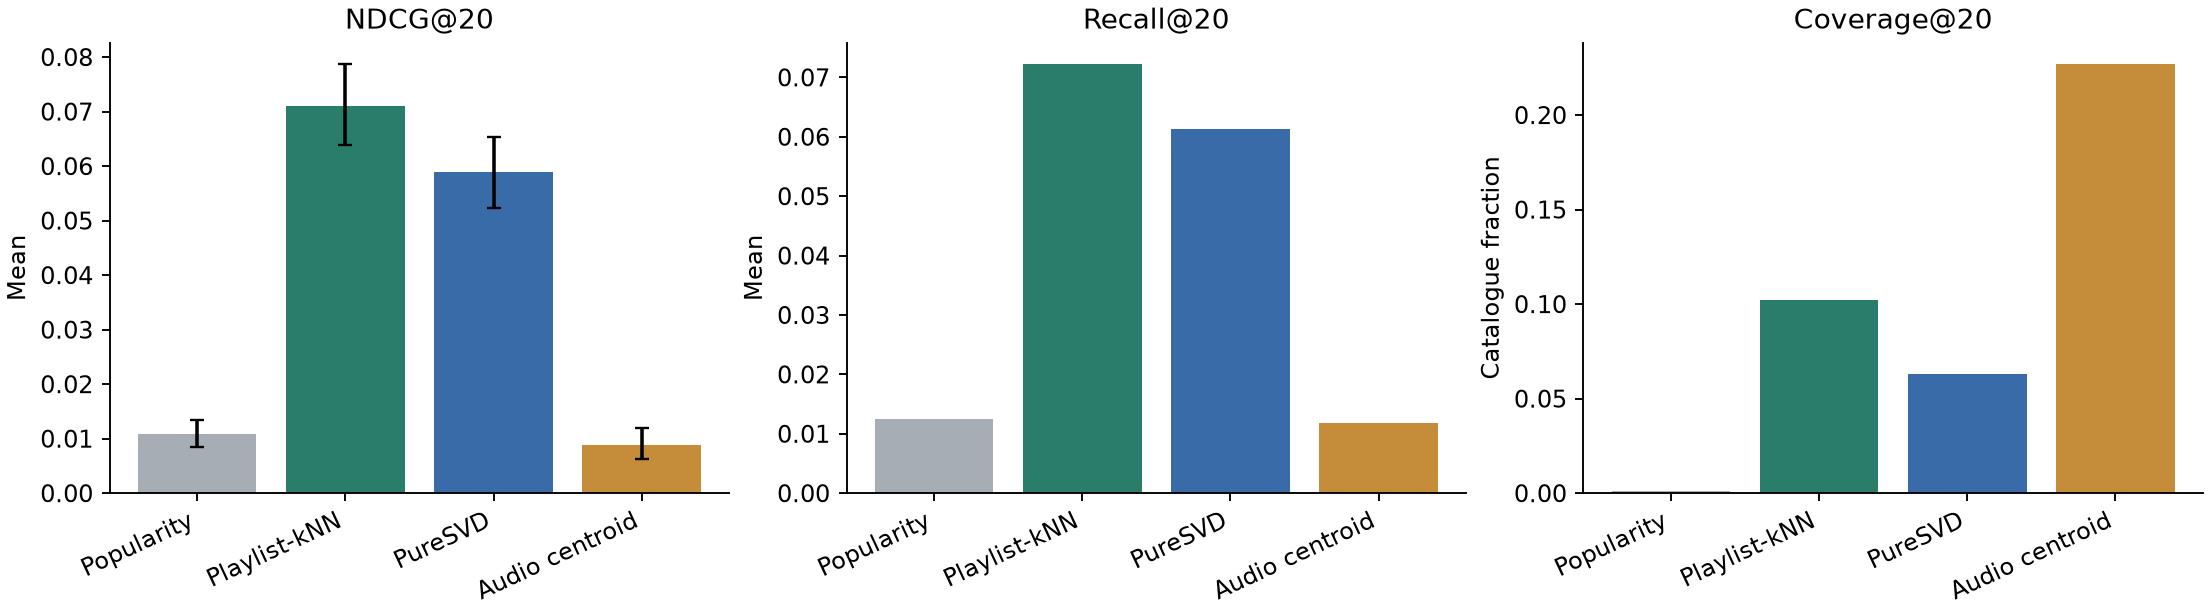

,model,delta_ndcg20_vs_popularity,ci_low,ci_high,p_two_sided,p_holm
0,Playlist-kNN,0.060163,0.053696,0.067266,0.000100,0.000300
1,PureSVD,0.048098,0.042392,0.053924,0.000100,0.000300
2,Audio centroid,-0.001961,-0.005620,0.002190,0.324368,0.324368


,model,NDCG@10,Recall@10,Precision@10,HitRate@10,NDCG@20,Recall@20,Precision@20,HitRate@20,NDCG@50,Recall@50,Precision@50,HitRate@50
0,Popularity,0.01049,0.00816,0.0090,0.065,0.01081,0.01244,0.00710,0.100,0.01573,0.02503,0.00610,0.183
1,Playlist-kNN,0.06969,0.05042,0.0536,0.330,0.07098,0.07222,0.04100,0.434,0.08875,0.12285,0.02886,0.570
2,PureSVD,0.05832,0.04312,0.0464,0.302,0.05891,0.06124,0.03445,0.376,0.07306,0.10215,0.02392,0.495
3,Audio centroid,0.00677,0.00609,0.0047,0.044,0.00885,0.01175,0.00525,0.090,0.01342,0.02446,0.00492,0.174


In [12]:
display(result_table[['model','NDCG@20','Recall@20','Precision@20','HitRate@20',
                      'Coverage@20','fit_seconds','rank_seconds']].round(5))
display(Image(filename=str(OUT / 'model_comparison.png')))
display(pd.read_csv(OUT / 'paired_comparisons.csv').round(6))
display(result_table[['model']+[f'{m}@{k}' for k in [10,20,50]
                              for m in ['NDCG','Recall','Precision','HitRate']]].round(5))

### 4.4 Main findings

**Playlist-kNN is the validation-selected model and has the strongest observed test
performance.** It reaches **NDCG@20 = 0.07098**, **Recall@20 = 0.07222**, and
**HitRate@20 = 0.434**. Popularity reaches **0.01081**, **0.01244**, and **0.100**,
respectively. The paired NDCG improvement is **0.06016**, with a 95% interval of
**[0.05370, 0.06727]** and Holm-adjusted p = **0.00030**. Thus shared-track
neighborhoods add a clear signal over overall fitting popularity on this split.
The sign-flip p-value is limited by the finite number of randomization draws.

**PureSVD also clearly improves over popularity**, reaching NDCG@20 = **0.05891**
and Recall@20 = **0.06124**. Its paired NDCG difference is **0.04810**
(95% interval **[0.04239, 0.05392]**, Holm-adjusted p = **0.00030**).
The kNN score is higher than SVD's, although the formal tests shown here compare
each model with popularity and do not test the kNN-SVD difference. Local overlaps
may preserve playlist-specific associations that a 64-dimensional reconstruction
smooths away; this is an interpretation, not an experimentally isolated cause.

**The audio-centroid model does not beat popularity overall.** Its test NDCG@20 is
**0.00885** and Recall@20 is **0.01175**. Its NDCG difference from popularity is
**-0.00196**, with interval **[-0.00562, 0.00219]** and adjusted p = **0.32437**.
The interval includes zero. Audio coherence in EDA therefore does not translate into
reliable exact-track recovery with this simple model. Artist identity, language,
semantic theme, and multi-modal playlist structure may matter beyond a centroid of
low-dimensional descriptors. Those explanations would need additional ablations.

Absolute recall remains modest: even kNN recovers about 7.2% of a playlist's held-out
tracks in its top 20, on average. This is a difficult sparse-catalogue task, and a
large improvement over a weak baseline is not equivalent to a production-ready system.

In [13]:
cold_share = experiment_summary['cold_test_interactions'] / experiment_summary['test_interactions']
print(f'Cold target interactions: {experiment_summary["cold_test_interactions"]:,} / '
      f'{experiment_summary["test_interactions"]:,} = {cold_share:.2%}')
display(result_table[['model','WarmRecall@20','ColdRecall@20','Coverage@20',
                      'ArtistDiversity@20','Novelty@20']].round(5))
display(pd.read_csv(OUT / 'length_subgroups.csv').round(5))

Cold target interactions: 5,623 / 12,698 = 44.28%


,model,WarmRecall@20,ColdRecall@20,Coverage@20,ArtistDiversity@20,Novelty@20
0,Popularity,0.01701,0.00000,0.00091,0.80565,5.10751
1,Playlist-kNN,0.11779,0.00000,0.10237,0.82675,6.45349
2,PureSVD,0.09147,0.00000,0.06314,0.82440,6.41060
3,Audio centroid,0.00522,0.01155,0.22689,0.95865,8.82414


,length_group,playlists,ndcg20,recall20,model
0,1-20 seeds,264,0.00638,0.01402,Popularity
1,21-50 seeds,336,0.00946,0.01245,Popularity
2,51+ seeds,400,0.01488,0.01140,Popularity
3,1-20 seeds,264,0.05242,0.07449,Playlist-kNN
4,21-50 seeds,336,0.06654,0.07789,Playlist-kNN
5,51+ seeds,400,0.08695,0.06595,Playlist-kNN
6,1-20 seeds,264,0.04208,0.06610,PureSVD
7,21-50 seeds,336,0.05694,0.06595,PureSVD
8,51+ seeds,400,0.07168,0.05408,PureSVD
9,1-20 seeds,264,0.01183,0.02210,Audio centroid


### 4.5 Cold tracks, coverage, and playlist length

**5,623 of 12,698 test interactions (44.3%)** concern tracks with zero interactions
in the final fitting matrix. This is a cold-interaction condition within a known
catalogue, not absence of metadata. Such tracks have no positive popularity or
neighborhood evidence, and SVD has no observed column signal. All three collaborative/
popularity approaches have zero cold-target Recall@20 in this run. The audio model
achieves **0.01155**. Warm Recall@20 is **0.11779** for kNN, **0.09147** for SVD,
**0.01701** for popularity, and **0.00522** for audio.

Warm and cold recalls are macro averages over the playlists with at least one target
of that type; they need not combine to the overall recall using the global cold
interaction fraction. Cold status is defined solely by the final fitting matrix.

The content model trades recovery for reach: it recommends **22.69%** of catalogue
tracks across its top-20 lists, compared with **10.24%** for kNN, **6.31%** for SVD,
and **0.091%** for popularity (33 distinct tracks). Audio also has higher artist
diversity and lower-popularity recommendations. These metrics show a different
behavior, not automatically better recommendations. A future hybrid could use
content for cold candidates and collaborative scores for warm candidates, but no
unrun hybrid result is claimed here.

For kNN, NDCG@20 is **0.0524**, **0.0665**, and **0.0869** for playlists with 1-20,
21-50, and 51+ fitting seeds. These groups contain 264, 336, and 400 playlists.
More seeds provide more context, but group differences also reflect playlist
content and target counts; they do not establish a causal benefit of adding seeds.

### 4.6 A fixed example and practical recommendation

The example below is playlist index 0, chosen in advance rather than selected for a
high score. `test_hit` means exact held-out membership, not a human relevance judgment.
Inspecting titles and artists helps explain the output, but does not replace the
full-catalogue comparison.

In [14]:
display(pd.read_csv(OUT / 'example_seeds.csv').head(12))
display(pd.read_csv(OUT / 'example_recommendations.csv'))

,track_name,artist_name
0,Bad Day,Daniel Powter
1,Smooth,Santana
2,I'd Rather Be With You [Radio Edit],Joshua Radin
3,Ordinary World,Duran Duran
4,One Headlight,The Wallflowers
5,Little Wonders - Radio Version,Rob Thomas
6,Animal,Neon Trees
7,Ho Hey,The Lumineers
8,Peaches,The Presidents Of The United States Of America
9,Kashmir,Led Zeppelin


,model,rank,track,artist,test_hit
0,Popularity,1,HUMBLE.,Kendrick Lamar,0
1,Popularity,2,Ignition - Remix,R. Kelly,0
2,Popularity,3,Bounce Back,Big Sean,0
3,Popularity,4,Broccoli (feat. Lil Yachty),DRAM,0
4,Popularity,5,Bad and Boujee (feat. Lil Uzi Vert),Migos,0
5,Popularity,6,XO TOUR Llif3,Lil Uzi Vert,0
6,Popularity,7,iSpy (feat. Lil Yachty),KYLE,0
7,Popularity,8,Location,Khalid,0
8,Popularity,9,DNA.,Kendrick Lamar,0
9,Popularity,10,Congratulations,Post Malone,0


For this dataset and completion setting, **use playlist-kNN with 50 neighbors and
cosine weights** as the primary method. It is simple, fast at this scale, and gives
the best validation and observed test performance. Keep popularity as a fallback.
PureSVD is a compact alternative; content deserves further study for tracks without
interaction evidence, despite its weak aggregate recovery.

The main limitations are the unverified extraction/enrichment history, a small
playlist sample, many singleton tracks, one random split, a known-playlist evaluation,
and incomplete relevance labels. There are no listener IDs or timestamps with which
to test personalization across people or chronological generalization. No listening
study establishes user satisfaction, diversity preference, or fairness. A larger
sample, repeated predefined splits, a new-playlist holdout, and a carefully validated
hybrid would provide stronger evidence. Test results here are final reporting, not
feedback for another round of tuning.

### References and relationship to the supplied slides

**[L1] Julian McAuley, course lecture, _Recommender Systems_ (`recommendation.pdf`).**
[Supplied Google Drive slides](https://drive.google.com/file/d/1VAt1C5Za5JCBXUkeRbqkH8jajgTdfmnl/view).
Relevant topics: similarity-based recommenders, cosine similarity, latent factors,
cold start, and precision/recall at K.

**[L2] Julian McAuley, course lecture, _Supervised learning - Regression_ (`regression.pdf`).**
[Supplied Google Drive slides](https://drive.google.com/file/d/19xh-0pTHUjTMNLFCGQVnPPgivAhbnpFX/view).
Relevant topics: categorical features, feature transforms, overfitting, regularization,
and train/validation/test separation.

**[L3] Course lecture, _Assignment 2_ (`assignment2_fa26.pdf`).**
[Supplied overview](https://drive.google.com/file/d/1CwsbNGf98gcQRfw2FPCpoRAoJoqlTbcQ/view).
Used for guidance on feature comparisons, baselines, scaling, and model selection.
Section numbering in this notebook follows the separately attached assignment PDF.

**[R1] Ching-Wei Chen (2020), _The Million Playlist Dataset... Remastered_.**
[Spotify Research](https://research.atspotify.com/2020/09/the-million-playlist-dataset-remastered).
Primary context for the original MPD and its playlist-continuation purpose;
it does not authenticate the local CSV's derivation.

**[R2] Hamed Zamani, Markus Schedl, Paul Lamere, and Ching-Wei Chen (2019),
_An Analysis of Approaches Taken in the ACM RecSys Challenge 2018 for Automatic
Music Playlist Continuation_.** [Paper](https://arxiv.org/abs/1810.01520).
The challenge studies continuation from seed tracks and metadata. Its evaluation
protocol differs from the present small-sample top-20 experiment, so its scores
are not used as comparable baselines.

**[R3] Irene Teinemaa, Niek Tax, and Carlos Bentes (2018), _Automatic Playlist
Continuation through a Composition of Collaborative Filters_.**
[Paper](https://arxiv.org/abs/1808.04288).
The authors combine collaborative filters for different playlist aspects. This
motivates testing interaction-based approaches; the present kNN/SVD comparison
does not reproduce their ensemble or optimization procedure.

**[R4] Andres Ferraro, Dmitry Bogdanov, Jisang Yoon, KwangSeob Kim, and Xavier Serra
(2018; arXiv 2019), _Automatic playlist continuation using a hybrid recommender
system combining features from text and audio_.**
[Paper](https://arxiv.org/abs/1901.00450).
Their system combines an audio/title-aware factorization model with a co-occurrence
model using ranking fusion. The simple audio-only centroid here is a much more
limited comparison; its negative aggregate result does not refute that hybrid approach.

### Reproducibility and verification

Run from the repository root with the dependencies in `requirements.txt` installed.
The notebook contains the preprocessing, model, and evaluation implementations;
`experiment.py` runs the same experiment from the command line. The dataset checksum,
package versions, split manifest, selected configurations, per-playlist metrics,
recommendations, and aggregate CSV tables are saved under `output/`.
`workbook.html` embeds tables and figures for review without a kernel or data download.

The notebook checks split disjointness, complete interaction accounting, nonempty
partitions, unique recommendations, and exclusion of seeds. The separate
`verify_experiment.py` checks ranking ties, exclusion of self-neighbors, hand-calculated
metrics, and the saved recommendation files. Times are measured on the current CPU
with numerical thread pools limited to four; they are not a hardware-independent benchmark.

In [15]:
display(pd.Series(experiment_summary['environment'], name='version'))
print('Dataset SHA-256:', experiment_summary['dataset_sha256'])
print('Output tables:', ', '.join(p.name for p in sorted(OUT.glob('*.csv'))))

python     3.14.4
numpy       2.5.5
pandas      3.1.1
scipy      1.18.1
sklearn     1.9.1
Name: version, dtype: str

Dataset SHA-256: 11533e4997668e7791c093bbcc63fb20ed820e8c4bbd80b7026fedaf1fb8d946
Output tables: audio_centroid_per_playlist.csv, audio_summary.csv, example_recommendations.csv, example_seeds.csv, item_vocabulary.csv, length_subgroups.csv, missingness.csv, paired_comparisons.csv, playlist-knn_per_playlist.csv, playlist_vocabulary.csv, popularity_per_playlist.csv, puresvd_per_playlist.csv, split_manifest.csv, test_results.csv, track_frequencies.csv, validation_results.csv
